원본 데이터 크기: (1941, 34)
원본 결측치 개수: 0

행별 결함 유형 개수:
1    1941
Name: count, dtype: int64

통합 후 데이터 크기: (1941, 27)

강종별 데이터 개수:
TypeOfSteel
A400    1164
A300     777
Name: count, dtype: int64

결함 유형별 데이터 개수:
결함유형
Other_Faults    673
Bumps           402
K_Scatch        391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: count, dtype: int64

비교할 파생 변수 개수: 12
파생 변수 목록: ['Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index']

파생 변수 포함 입력 변수 수: 26
파생 변수 제외 입력 변수 수: 14

파생 변수 제외 후 남은 변수:
['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'Steel_Plate_Thickness', 'SigmoidOfAreas', 'TypeOfSteel']

제거한 전체 결측 변수: []
제거한 상수 변수: []

데이터 분리 결과
학습: 1164
검증: 388
테스트: 389

파생 변수 포

,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Condition,Model,Fit Time (sec)
7,0.791237,0.824148,0.784735,0.798882,0.786485,파생 변수 제외,Tuned Random Forest,3.85
4,0.747423,0.775938,0.775506,0.773536,0.750544,파생 변수 제외,Random Forest,0.25
5,0.755155,0.811735,0.745012,0.768101,0.747932,파생 변수 제외,Extra Trees,0.20
6,0.579897,0.531353,0.664434,0.556445,0.572010,파생 변수 제외,Logistic Regression,0.03
3,0.793814,0.823743,0.810232,0.816315,0.795158,파생 변수 포함,Tuned Random Forest,7.84
0,0.768041,0.821018,0.806568,0.810112,0.771304,파생 변수 포함,Random Forest,0.28
1,0.765464,0.817059,0.751606,0.774848,0.760616,파생 변수 포함,Extra Trees,0.22
2,0.641753,0.614623,0.734963,0.642527,0.635086,파생 변수 포함,Logistic Regression,0.04



파생 변수 포함 선택 모델: Tuned Random Forest
검증 Macro F1: 0.8163

파생 변수 제외 선택 모델: Tuned Random Forest
검증 Macro F1: 0.7989

파생 변수 포함 - Tuned Random Forest

결함 유형별 평가:
              precision    recall  f1-score   support

      Pastry       0.64      0.68      0.66        31
   Z_Scratch       0.95      0.95      0.95        38
    K_Scatch       1.00      0.82      0.90        79
      Stains       0.86      0.86      0.86        14
   Dirtiness       0.90      0.82      0.86        11
       Bumps       0.67      0.69      0.68        81
Other_Faults       0.71      0.76      0.74       135

    accuracy                           0.78       389
   macro avg       0.82      0.80      0.81       389
weighted avg       0.79      0.78      0.78       389


파생 변수 제외 - Tuned Random Forest

결함 유형별 평가:
              precision    recall  f1-score   support

      Pastry       0.67      0.39      0.49        31
   Z_Scratch       0.97      0.95      0.96        38
    K_Scatch       0.99      0.89     

,Condition,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,파생 변수 포함,Tuned Random Forest,0.776350,0.816841,0.796745,0.805026,0.779936
1,파생 변수 제외,Tuned Random Forest,0.773779,0.806176,0.754147,0.773497,0.771762


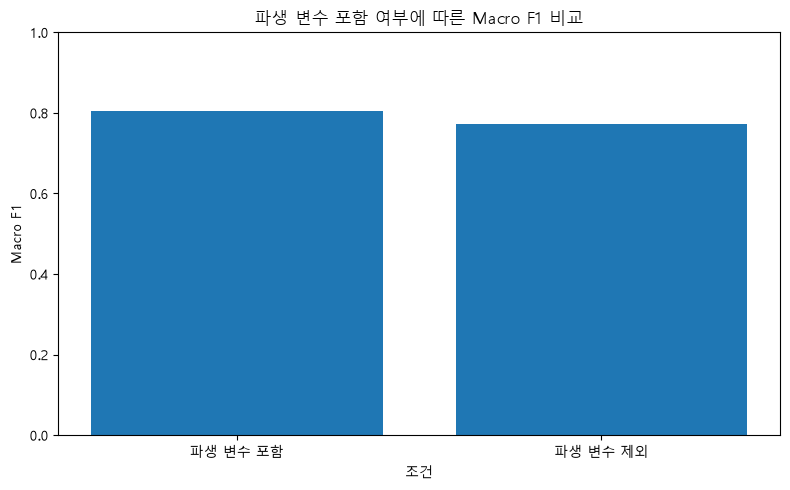

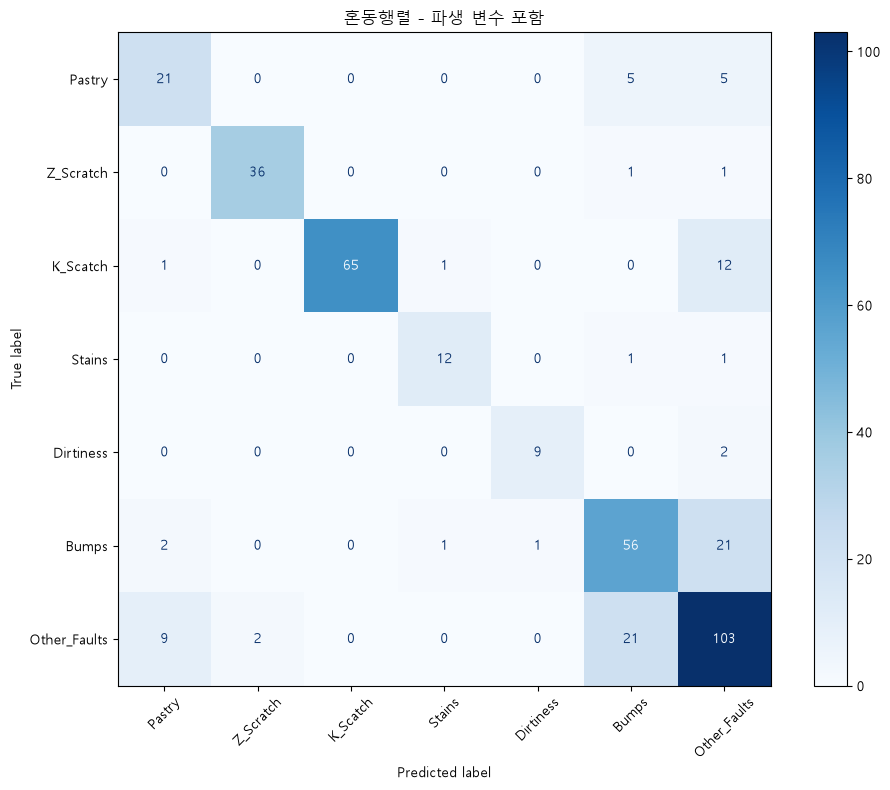

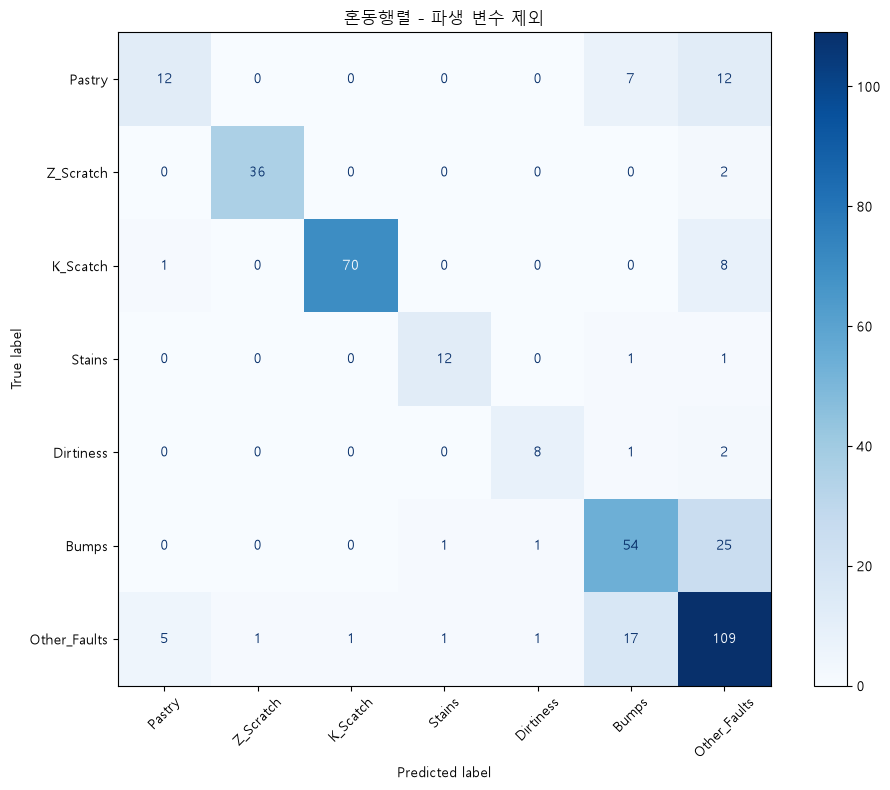


성능 차이:


,지표,파생 변수 포함,파생 변수 제외,차이(포함 - 제외)
0,Accuracy,0.7763,0.7738,0.0026
1,Macro Precision,0.8168,0.8062,0.0107
2,Macro Recall,0.7967,0.7541,0.0426
3,Macro F1,0.8050,0.7735,0.0315
4,Weighted F1,0.7799,0.7718,0.0082



모든 분석 완료!
결과 저장 폴더: steel_faults_results


In [ ]:
## 강종 한 열, 결함 유형 한 열, 파생 변수 있 없 성능 비교 -> 있는 게 성능이 나았음

# ============================================================
# 1. 라이브러리 및 환경 설정
# ============================================================

import os
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
DATA_PATH = "steel_plates_faults.csv"
RESULT_DIR = "steel_faults_results"

os.makedirs(RESULT_DIR, exist_ok=True)

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


# ============================================================
# 2. 데이터 불러오기
# ============================================================

df = pd.read_csv(DATA_PATH)

print("원본 데이터 크기:", df.shape)
print("원본 결측치 개수:", df.isna().sum().sum())


# ============================================================
# 3. 결함 유형 7개를 하나의 열로 통합
# ============================================================

target_cols = [
    "Pastry", "Z_Scratch", "K_Scatch",
    "Stains", "Dirtiness", "Bumps", "Other_Faults"
]

steel_cols = ["TypeOfSteel_A300", "TypeOfSteel_A400"]

required_cols = target_cols + steel_cols
missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    raise ValueError(f"필요한 열이 없습니다: {missing_cols}")

df[target_cols] = df[target_cols].apply(
    pd.to_numeric, errors="raise"
)

if not df[target_cols].isin([0, 1]).all().all():
    raise ValueError("결함 유형 열에 0 또는 1이 아닌 값이 있습니다.")

fault_count = df[target_cols].sum(axis=1)

print("\n행별 결함 유형 개수:")
print(fault_count.value_counts().sort_index())

if not (fault_count == 1).all():
    raise ValueError(
        "결함 유형이 0개 또는 2개 이상인 행이 있습니다."
    )

df["결함유형"] = df[target_cols].idxmax(axis=1)
df.drop(columns=target_cols, inplace=True)


# ============================================================
# 4. 강종 두 열을 하나의 열로 통합
# ============================================================

df[steel_cols] = df[steel_cols].apply(
    pd.to_numeric, errors="raise"
)

if not df[steel_cols].isin([0, 1]).all().all():
    raise ValueError("강종 열에 0 또는 1이 아닌 값이 있습니다.")

steel_count = df[steel_cols].sum(axis=1)

if not (steel_count == 1).all():
    raise ValueError(
        "강종이 지정되지 않았거나 두 강종이 동시에 표시된 행이 있습니다."
    )

# 0 = A300, 1 = A400
df["TypeOfSteel"] = df["TypeOfSteel_A400"].astype(int)

df.drop(columns=steel_cols, inplace=True)

print("\n통합 후 데이터 크기:", df.shape)
print("\n강종별 데이터 개수:")
print(df["TypeOfSteel"].map({0: "A300", 1: "A400"}).value_counts())

print("\n결함 유형별 데이터 개수:")
print(df["결함유형"].value_counts())


# ============================================================
# 5. 파생 변수 목록 정의
# ============================================================

derived_cols = [
    "Edges_Index",
    "Empty_Index",
    "Square_Index",
    "Outside_X_Index",
    "Edges_X_Index",
    "Edges_Y_Index",
    "Outside_Global_Index",
    "LogOfAreas",
    "Log_X_Index",
    "Log_Y_Index",
    "Orientation_Index",
    "Luminosity_Index"
]

missing_derived = [
    col for col in derived_cols if col not in df.columns
]

if missing_derived:
    raise ValueError(
        f"파생 변수 열을 찾을 수 없습니다: {missing_derived}"
    )

print("\n비교할 파생 변수 개수:", len(derived_cols))
print("파생 변수 목록:", derived_cols)


# ============================================================
# 6. 입력 변수 구성
# ============================================================

y = df["결함유형"].copy()

X_all = df.drop(columns=["결함유형"]).copy()

X_all = X_all.apply(pd.to_numeric, errors="coerce")
X_all = X_all.replace([np.inf, -np.inf], np.nan)

# 모든 값이 결측치인 변수는 두 조건에서 공통으로 제거
all_missing_cols = X_all.columns[X_all.isna().all()].tolist()

if all_missing_cols:
    X_all.drop(columns=all_missing_cols, inplace=True)

# 상수 변수도 두 조건에서 공통으로 제거
constant_cols = X_all.columns[
    X_all.nunique(dropna=False) <= 1
].tolist()

if constant_cols:
    X_all.drop(columns=constant_cols, inplace=True)

# 파생 변수를 포함하는 조건
X_with = X_all.copy()

# 파생 변수를 제외하는 조건
X_without = X_all.drop(
    columns=derived_cols,
    errors="raise"
).copy()

print("\n파생 변수 포함 입력 변수 수:", X_with.shape[1])
print("파생 변수 제외 입력 변수 수:", X_without.shape[1])

print("\n파생 변수 제외 후 남은 변수:")
print(X_without.columns.tolist())

print("\n제거한 전체 결측 변수:", all_missing_cols)
print("제거한 상수 변수:", constant_cols)


# ============================================================
# 7. 동일한 학습 / 검증 / 테스트 데이터 분리
#    학습 60% / 검증 20% / 테스트 20%
# ============================================================

# 인덱스를 기준으로 같은 행을 동일한 분할에 사용
train_idx, temp_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.4,
    random_state=RANDOM_STATE,
    stratify=y
)

valid_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=y.iloc[temp_idx]
)

X_train_with = X_with.iloc[train_idx]
X_valid_with = X_with.iloc[valid_idx]
X_test_with = X_with.iloc[test_idx]

X_train_without = X_without.iloc[train_idx]
X_valid_without = X_without.iloc[valid_idx]
X_test_without = X_without.iloc[test_idx]

y_train = y.iloc[train_idx]
y_valid = y.iloc[valid_idx]
y_test = y.iloc[test_idx]

print("\n데이터 분리 결과")
print("학습:", len(train_idx))
print("검증:", len(valid_idx))
print("테스트:", len(test_idx))


# ============================================================
# 8. 평가 함수
# ============================================================

def evaluate_model(model, X_data, y_data):
    y_pred = model.predict(X_data)

    return {
        "Accuracy": accuracy_score(y_data, y_pred),
        "Macro Precision": precision_score(
            y_data, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_data, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_data, y_pred,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_data, y_pred,
            average="weighted",
            zero_division=0
        )
    }


# ============================================================
# 9. 기본 모델 생성 함수
# ============================================================

def create_models():
    return {
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
        ]),

        "Extra Trees": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", ExtraTreesClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
        ]),

        "Logistic Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=3000,
                class_weight="balanced",
                random_state=RANDOM_STATE
            ))
        ])
    }


# ============================================================
# 10. Random Forest 튜닝 함수
# ============================================================

param_dist = {
    "model__n_estimators": [200, 300, 500, 700],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10, 15],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": ["sqrt", 0.5, 0.8],
    "model__class_weight": ["balanced", "balanced_subsample"]
}


def tune_random_forest(X_train):
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=1
        ))
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_dist,
        n_iter=25,
        scoring="f1_macro",
        cv=3,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    start = time.time()
    search.fit(X_train, y_train)
    elapsed = time.time() - start

    return search, elapsed


# ============================================================
# 11. 파생 변수 포함 / 제외 각각 모델링
# ============================================================

conditions = {
    "파생 변수 포함": (
        X_train_with,
        X_valid_with
    ),
    "파생 변수 제외": (
        X_train_without,
        X_valid_without
    )
}

all_results = []
trained_models = {}
search_results = {}
fit_times = {}

for condition, (X_train_cond, X_valid_cond) in conditions.items():

    print("\n" + "=" * 60)
    print(condition)
    print("=" * 60)

    models = create_models()

    # 기본 모델 3개 학습
    for model_name, model in models.items():

        start = time.time()
        model.fit(X_train_cond, y_train)
        elapsed = time.time() - start

        metrics = evaluate_model(
            model, X_valid_cond, y_valid
        )

        metrics["Condition"] = condition
        metrics["Model"] = model_name
        metrics["Fit Time (sec)"] = round(elapsed, 2)

        all_results.append(metrics)
        trained_models[(condition, model_name)] = model
        fit_times[(condition, model_name)] = elapsed

    # Random Forest 튜닝
    search, tuning_time = tune_random_forest(X_train_cond)

    tuned_model = search.best_estimator_

    metrics = evaluate_model(
        tuned_model, X_valid_cond, y_valid
    )

    metrics["Condition"] = condition
    metrics["Model"] = "Tuned Random Forest"
    metrics["Fit Time (sec)"] = round(tuning_time, 2)

    all_results.append(metrics)
    trained_models[(condition, "Tuned Random Forest")] = tuned_model
    search_results[condition] = search
    fit_times[(condition, "Tuned Random Forest")] = tuning_time

    print("\n최적 하이퍼파라미터:")
    print(search.best_params_)
    print("최고 교차검증 Macro F1:", round(search.best_score_, 4))


# ============================================================
# 12. 검증 성능 비교
# ============================================================

validation_results = pd.DataFrame(all_results)

validation_results = validation_results.sort_values(
    ["Condition", "Macro F1"],
    ascending=[True, False]
)

print("\n전체 검증 성능 비교:")
display(validation_results)

validation_results.to_csv(
    f"{RESULT_DIR}/derived_feature_validation_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 13. 각 조건에서 Macro F1이 가장 높은 모델 선택
# ============================================================

selected_models = {}

for condition in conditions:

    condition_results = validation_results[
        validation_results["Condition"] == condition
    ]

    best_row = condition_results.loc[
        condition_results["Macro F1"].idxmax()
    ]

    model_name = best_row["Model"]

    selected_models[condition] = {
        "model_name": model_name,
        "model": trained_models[(condition, model_name)]
    }

    print(
        f"\n{condition} 선택 모델: {model_name}"
    )
    print(
        "검증 Macro F1:",
        round(best_row["Macro F1"], 4)
    )


# ============================================================
# 14. 테스트 데이터 최종 평가
# ============================================================

test_inputs = {
    "파생 변수 포함": X_test_with,
    "파생 변수 제외": X_test_without
}

test_results = []
test_predictions = {}

for condition, X_test_cond in test_inputs.items():

    model_name = selected_models[condition]["model_name"]
    model = selected_models[condition]["model"]

    y_pred = model.predict(X_test_cond)
    test_predictions[condition] = y_pred

    metrics = evaluate_model(model, X_test_cond, y_test)

    metrics["Condition"] = condition
    metrics["Model"] = model_name

    test_results.append(metrics)

    print("\n" + "=" * 50)
    print(condition, "-", model_name)
    print("=" * 50)

    print("\n결함 유형별 평가:")
    print(classification_report(
        y_test,
        y_pred,
        labels=target_cols,
        zero_division=0
    ))

test_results_df = pd.DataFrame(test_results)

print("\n최종 테스트 성능 비교:")
display(
    test_results_df[
        [
            "Condition", "Model", "Accuracy",
            "Macro Precision", "Macro Recall",
            "Macro F1", "Weighted F1"
        ]
    ]
)

test_results_df.to_csv(
    f"{RESULT_DIR}/derived_feature_test_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 15. 테스트 Macro F1 비교 그래프
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    test_results_df["Condition"],
    test_results_df["Macro F1"]
)

plt.title("파생 변수 포함 여부에 따른 Macro F1 비교")
plt.xlabel("조건")
plt.ylabel("Macro F1")
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/04_derived_feature_macro_f1.png",
    dpi=150
)

plt.show()


# ============================================================
# 16. 혼동행렬 저장
# ============================================================

for condition, X_test_cond in test_inputs.items():

    model_name = selected_models[condition]["model_name"]
    y_pred = test_predictions[condition]

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=target_cols
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=target_cols
    )

    fig, ax = plt.subplots(figsize=(10, 8))
    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"혼동행렬 - {condition}")
    plt.xticks(rotation=45)
    plt.tight_layout()

    filename = (
        "05_confusion_with.png"
        if condition == "파생 변수 포함"
        else "06_confusion_without.png"
    )

    plt.savefig(
        f"{RESULT_DIR}/{filename}",
        dpi=150
    )

    plt.show()


# ============================================================
# 17. 성능 차이 계산
# ============================================================

with_row = test_results_df[
    test_results_df["Condition"] == "파생 변수 포함"
].iloc[0]

without_row = test_results_df[
    test_results_df["Condition"] == "파생 변수 제외"
].iloc[0]

comparison = pd.DataFrame({
    "지표": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1"
    ],
    "파생 변수 포함": [
        with_row["Accuracy"],
        with_row["Macro Precision"],
        with_row["Macro Recall"],
        with_row["Macro F1"],
        with_row["Weighted F1"]
    ],
    "파생 변수 제외": [
        without_row["Accuracy"],
        without_row["Macro Precision"],
        without_row["Macro Recall"],
        without_row["Macro F1"],
        without_row["Weighted F1"]
    ]
})

comparison["차이(포함 - 제외)"] = (
    comparison["파생 변수 포함"]
    - comparison["파생 변수 제외"]
)

print("\n성능 차이:")
display(comparison.round(4))

comparison.to_csv(
    f"{RESULT_DIR}/derived_feature_performance_difference.csv",
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 18. 최종 모델 저장
# ============================================================

for condition, selected in selected_models.items():

    filename = (
        "best_model_with_derived.pkl"
        if condition == "파생 변수 포함"
        else "best_model_without_derived.pkl"
    )

    joblib.dump(
        selected["model"],
        f"{RESULT_DIR}/{filename}"
    )


# ============================================================
# 19. 실행 정보 저장
# ============================================================

run_info = {
    "target_column": "결함유형",
    "steel_type_encoding": {
        "0": "A300",
        "1": "A400"
    },
    "derived_features": derived_cols,
    "removed_all_missing_features": all_missing_cols,
    "removed_constant_features": constant_cols,
    "random_state": RANDOM_STATE,
    "split": {
        "train": 0.6,
        "validation": 0.2,
        "test": 0.2
    },
    "selected_models": {},
    "test_metrics": {}
}

for condition, selected in selected_models.items():

    run_info["selected_models"][condition] = selected["model_name"]

    row = test_results_df[
        test_results_df["Condition"] == condition
    ].iloc[0]

    run_info["test_metrics"][condition] = {
        metric: float(row[metric])
        for metric in [
            "Accuracy",
            "Macro Precision",
            "Macro Recall",
            "Macro F1",
            "Weighted F1"
        ]
    }

    if condition in search_results:
        search = search_results[condition]

        run_info.setdefault("best_params", {})[condition] = (
            search.best_params_
        )

        run_info.setdefault("cv_best_macro_f1", {})[condition] = (
            float(search.best_score_)
        )

with open(
    f"{RESULT_DIR}/derived_feature_run_info.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        run_info,
        f,
        ensure_ascii=False,
        indent=4
    )

print("\n모든 분석 완료!")
print("결과 저장 폴더:", RESULT_DIR)